# Kilitli tahminlerle bağımsız test

Aşağıdaki çıktılar uzak GitHub kilidi doğrulandıktan sonra hesaplandı. Görüntüleme hücreleri modeli yeniden eğitmez veya sonucu yeniden hesaplamaz.

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path.cwd()
if not (ROOT / "src/experiment.py").exists():
    ROOT = ROOT / "YapayS-Vize"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/JustLotus/YapayS-Vize.git",
                        str(ROOT)], check=True)
import pandas as pd
from IPython.display import Image, display

def table(name, maximum=None):
    frame = pd.read_csv(ROOT / "results" / name)
    if maximum is not None:
        frame = frame.head(maximum)
    display(frame.round(4))

def figure(name, width=680):
    display(Image(filename=str(ROOT / "figures" / name), width=width))


In [2]:
# Yeniden üretmek için temiz bir depo kopyasında True yapın.
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(ROOT / "requirements.txt")], check=True)
    for stage in ('evaluate',):
        subprocess.run([sys.executable, "src/experiment.py", stage], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "src/make_report.py"], cwd=ROOT, check=True)


In [3]:
import json
for name in ("evaluation_provenance", "bootstrap_intervals"):
    print(json.dumps(json.loads((ROOT / f"results/{name}.json").read_text(encoding="utf-8")), indent=2))
table("test_metrics.csv")
table("seed_stability_results.csv")
table("seed_stability_summary.csv")
table("error_type_counts.csv")


{
  "prediction_lock_commit": "3d0cdf9e0c2fb5011482fa5d8d10574a7272499e",
  "threshold": 0.5,
  "prediction_sha256": "1723079b65620d0c3b3023c92246d4f21068e8a2ded72fa3f3930d2c6f021d27",
  "bootstrap_replicates": 1000,
  "bootstrap_seed": 31663
}
{
  "ROC_AUC": [
    0.7512058348283878,
    0.8571431417003845
  ],
  "AP": [
    0.34177193701426645,
    0.5649264817565902
  ],
  "F1": [
    0.15253833736884587,
    0.3697634609399315
  ]
}


,method,seconds,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy
0,MLP,0.6018,0.4385,0.8071,0.8993,0.6522,0.1667,0.9891,0.2655,0.5779
1,LogisticRegression,0.0582,0.4736,0.8102,0.9029,0.6923,0.2000,0.9891,0.3103,0.5946
2,Dummy,0.0308,0.1092,0.5000,0.8908,0.0000,0.0000,1.0000,0.0000,0.5000


,seed,seconds,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy
0,31163,0.6018,0.4385,0.8071,0.8993,0.6522,0.1667,0.9891,0.2655,0.5779
1,31164,0.5720,0.4515,0.7843,0.9005,0.6818,0.1667,0.9905,0.2679,0.5786
2,31165,0.6136,0.4507,0.8037,0.8981,0.6154,0.1778,0.9864,0.2759,0.5821


,group,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Sensitivity_mean,Sensitivity_std,Specificity_mean,Specificity_std,F1_mean,F1_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,seconds_mean,seconds_std
0,MLP,0.4469,0.0073,0.7984,0.0122,0.8993,0.0012,0.6498,0.0333,0.1704,0.0064,0.9886,0.0021,0.2697,0.0054,0.5795,0.0023,0.5958,0.0214


,type,count
0,correct,741
1,FN,75
2,FP,8


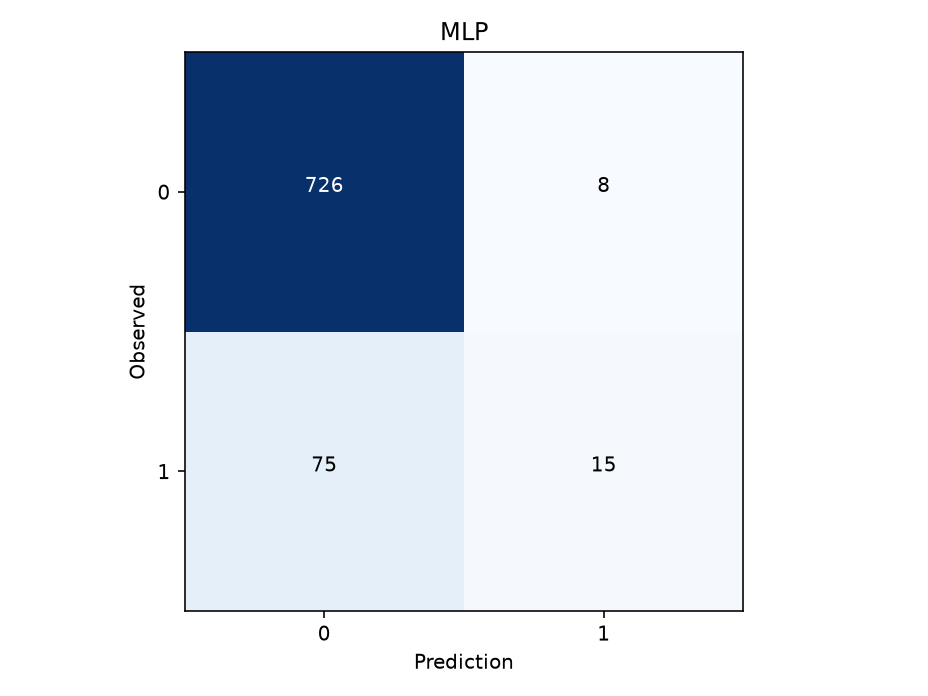

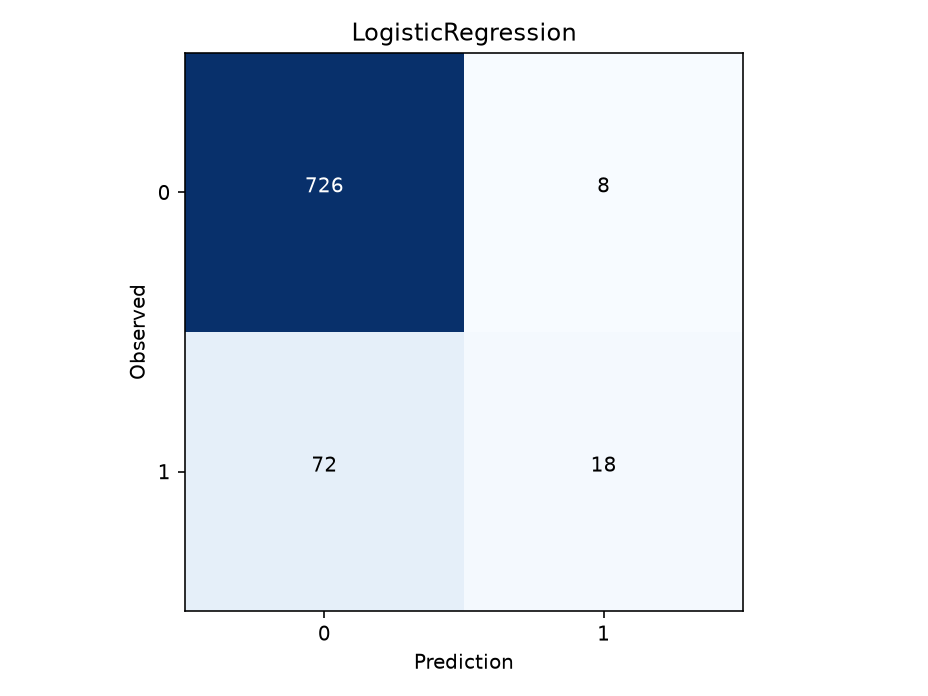

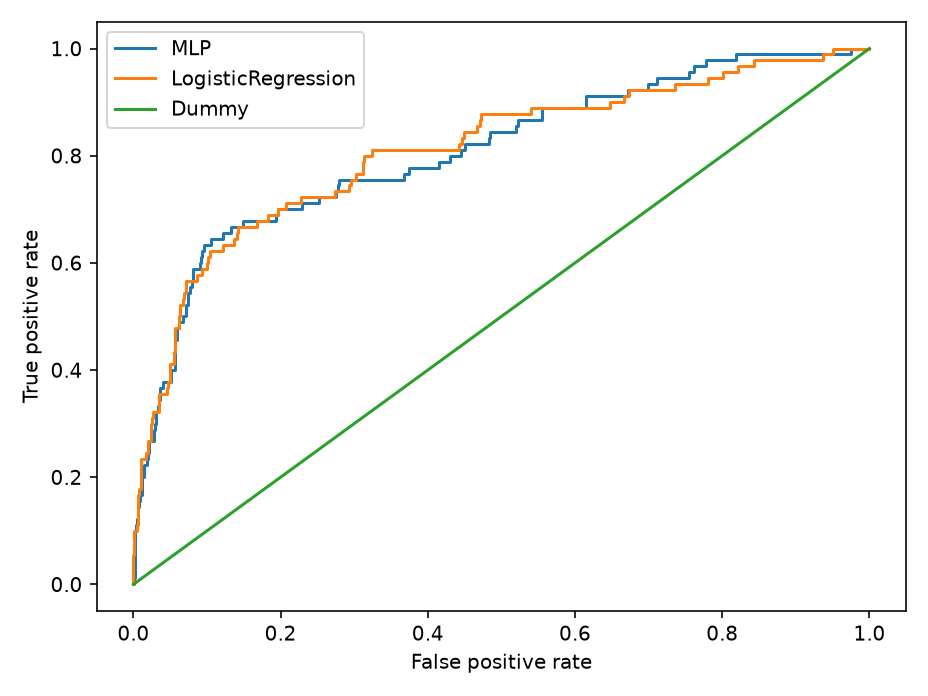

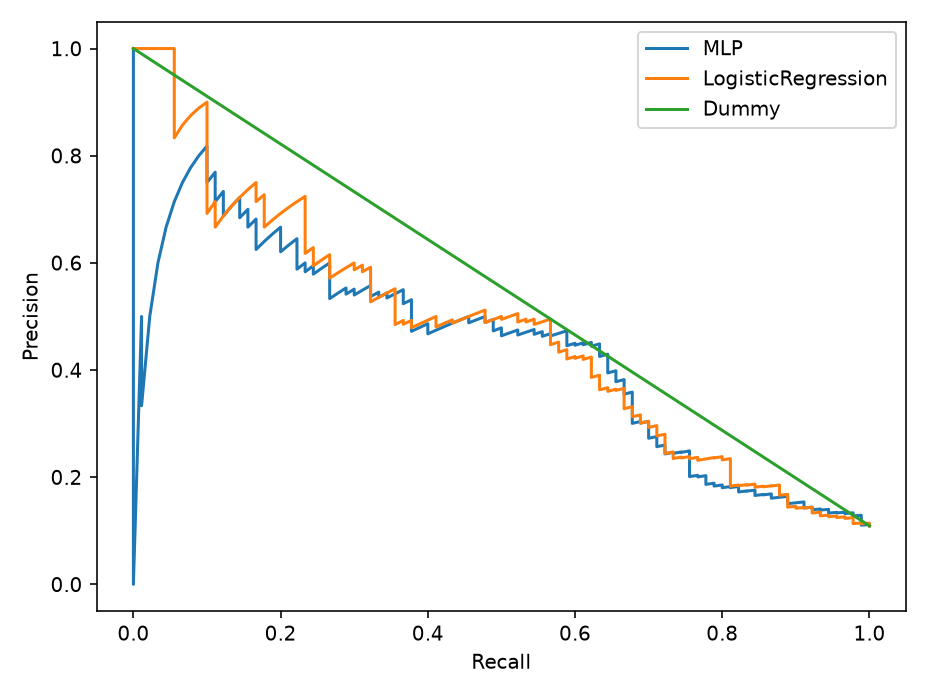

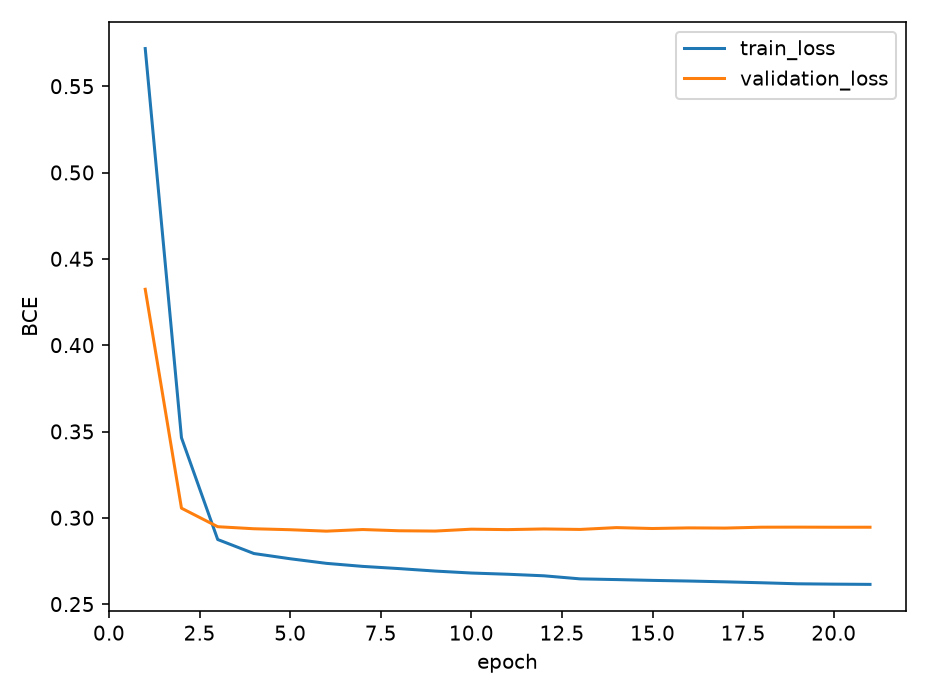

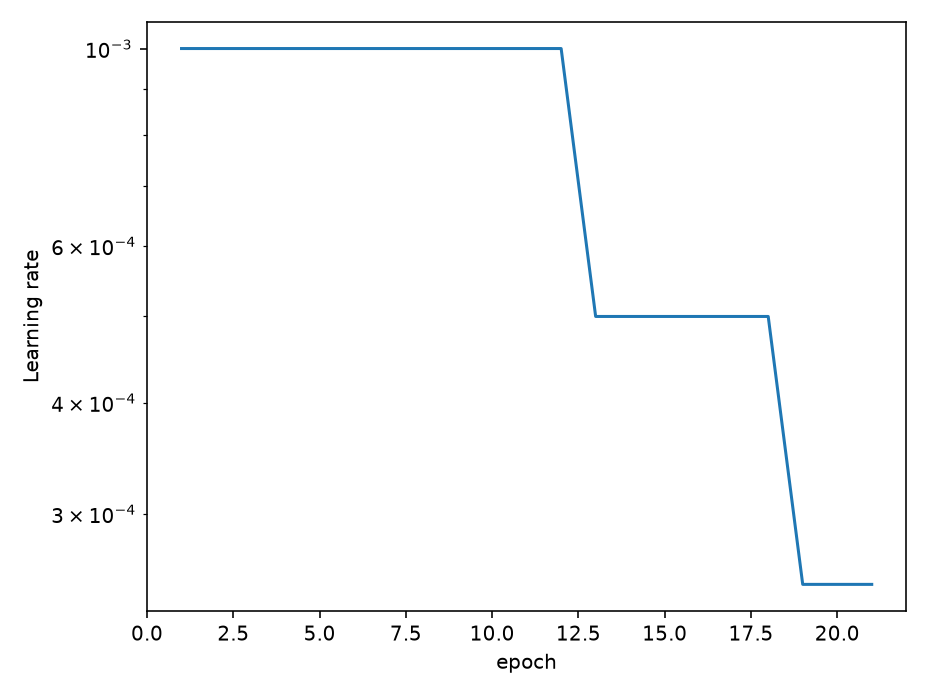

In [4]:
for name in ("test_confusion_MLP.png", "test_confusion_LogisticRegression.png",
             "test_roc.png", "test_pr.png", "final_learning_curves.png", "final_learning_rate.png"):
    figure(name)